# Experiências de comunicação com e sem SA

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

# Comunicação e PR-AUC — FedAvg vs Soft Labels

**Comparação emparelhada com/sem SA dentro de cada abordagem.** Mesmos IDs, cinco seeds (2031–2035), três rondas e dez épocas locais. 22 clientes, pesos de fit: 72,73% Icentia e 27,27% PhysioNet. Sem desistências nesta comparação. SA: soma única, 24 bits, limiar 12. FedAvg usa CNN1D comum; Soft Labels usa professores AE+CNN/MobileNetV2 e aluno CNN1D. A diferença entre abordagens inclui arquitetura/objetivo e custo de treino distintos; as épocas iguais não igualam FLOPs.

{'status': 'complete', 'validated_runs': 20, 'signature': '590f95d2e0ae0804092eeab9326543fffa70e3b18e6d11584e39f0b18bdacb98'}

**20/20 execuções concluídas e validadas.** Barras parciais só incluem execuções completas; `n` indica seeds disponíveis.

PR-AUC local: professor no próprio holdout nas Soft Labels; rede local após treino, antes da agregação, em FedAvg. PR-AUC global: o modelo global avaliado nos mesmos holdouts. Média ponderada dos AP individuais, não uma curva conjunta. O modelo FedAvg entregue ao cliente após agregação corresponde à barra global. Dev é secundário e está nas tabelas por cliente; test não é usado. AP indefinida num holdout com uma só classe é excluída, com cobertura explícita nas tabelas.

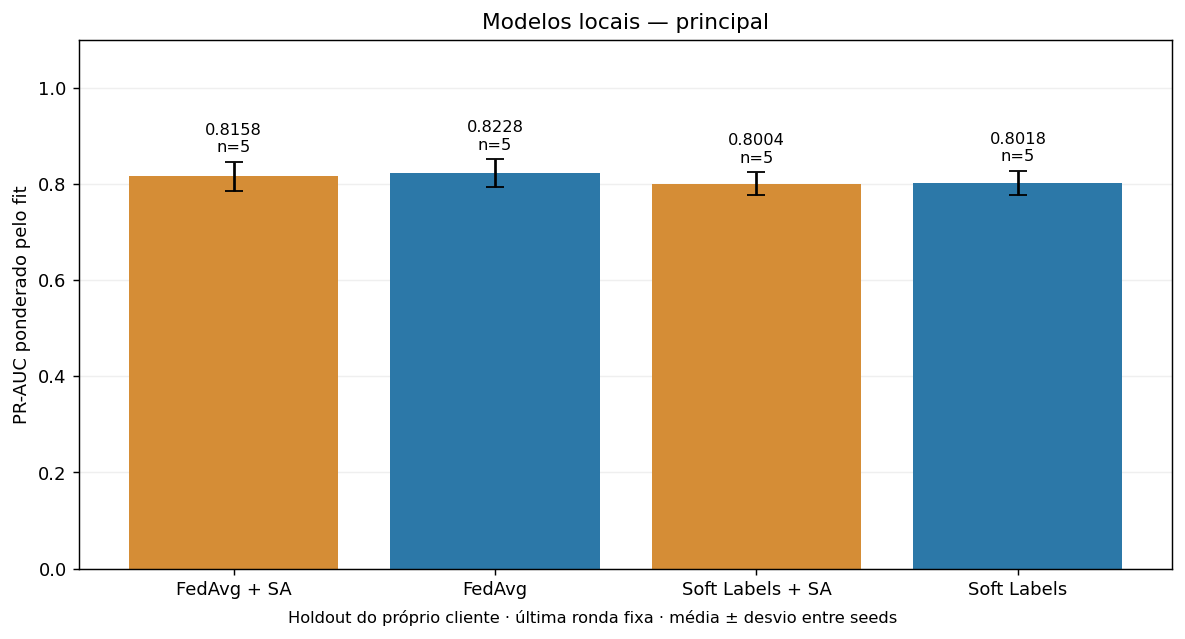

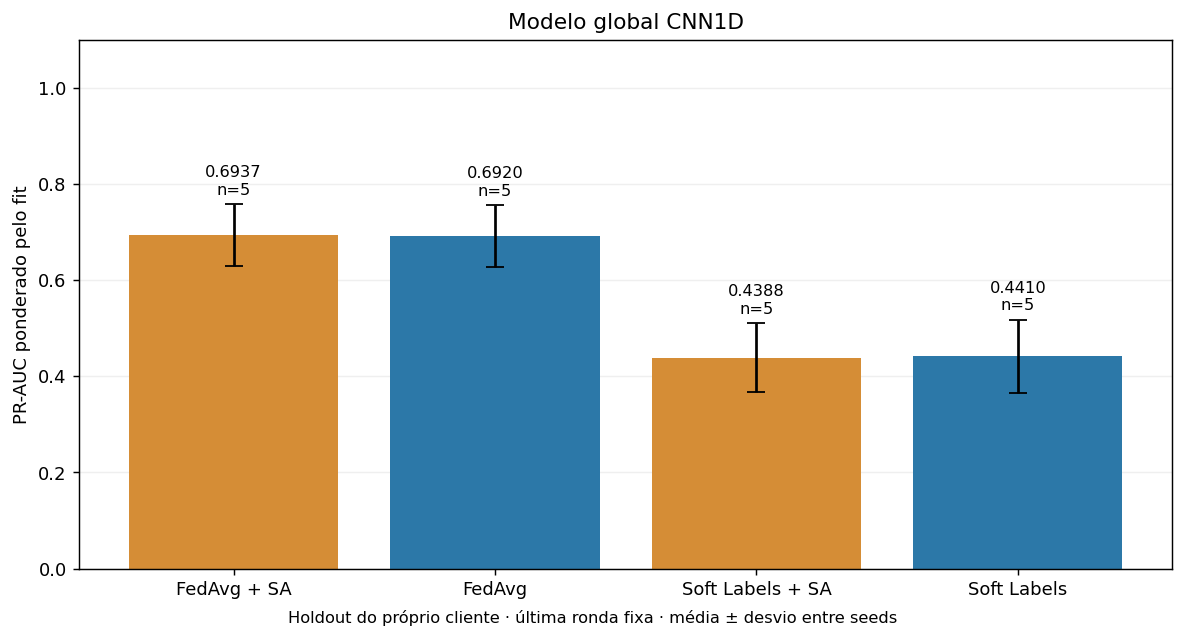

algorithm,condition,seed,role,pr_auc_ap,roc_auc,recall,far,f1,valid_ap_clients,total_clients,ap_fit_coverage
Fedavg,SA,2031,global,0.727394,0.764464,0.290210,0.274194,0.182828,22,22,1.0
Fedavg,SA,2031,local,0.860756,0.883316,0.733204,0.135852,0.654203,22,22,1.0
Fedavg,SA,2032,global,0.730543,0.801078,0.276224,0.274194,0.164069,22,22,1.0
Fedavg,SA,2032,local,0.779755,0.859246,0.763299,0.164325,0.708451,22,22,1.0
Fedavg,SA,2033,global,0.580844,0.682743,0.272727,0.270335,0.158173,22,22,1.0
Fedavg,SA,2033,local,0.800281,0.874612,0.742632,0.174419,0.624778,22,22,1.0
Fedavg,SA,2034,global,0.701986,0.790911,0.395979,0.274348,0.290673,22,22,1.0
Fedavg,SA,2034,local,0.809161,0.864540,0.733142,0.126346,0.689620,22,22,1.0
Fedavg,SA,2035,global,0.727918,0.814865,0.272727,0.270335,0.158173,22,22,1.0
Fedavg,SA,2035,local,0.828837,0.874964,0.731831,0.103813,0.688946,22,22,1.0


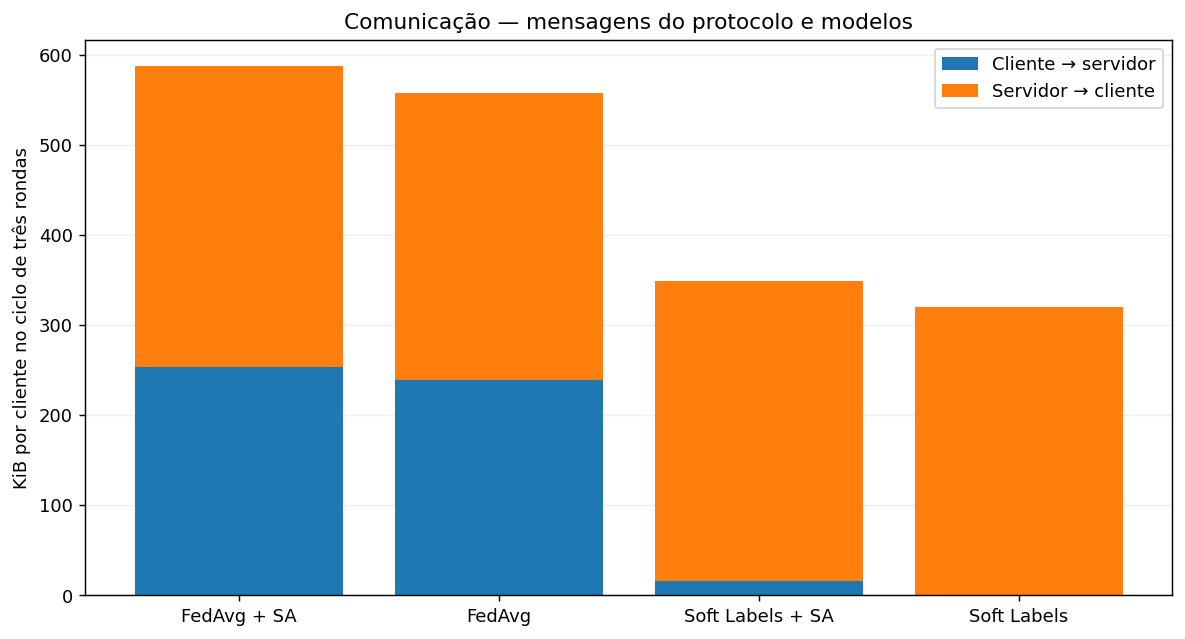

algorithm,condition,seed,upload_bytes,download_bytes,total_bytes,aggregation_seconds,local_compute_seconds
Fedavg,SA,2031,5720088,7509920,13230008,4.235094,23.838401
Fedavg,SA,2032,5720088,7509920,13230008,6.205324,34.948589
Fedavg,SA,2033,5720088,7509920,13230008,4.406528,24.905172
Fedavg,SA,2034,5720088,7509920,13230008,4.180660,22.515737
Fedavg,SA,2035,5720088,7509920,13230008,9.928714,60.105515
Fedavg,plain,2031,5387184,7182560,12569744,0.000464,24.492564
Fedavg,plain,2032,5387184,7182560,12569744,0.000680,33.012817
Fedavg,plain,2033,5387184,7182560,12569744,0.000508,26.301538
Fedavg,plain,2034,5387184,7182560,12569744,0.000475,24.001517
Fedavg,plain,2035,5387184,7182560,12569744,0.000781,43.316742


condition,algorithm,seed,role,SA,plain,SA_minus_plain
,Fedavg,2031,global,0.727394,0.727698,-0.000303
,Fedavg,2031,local,0.860756,0.861118,-0.000362
,Fedavg,2032,global,0.730543,0.731184,-0.000641
,Fedavg,2032,local,0.779755,0.780141,-0.000387
,Fedavg,2033,global,0.580844,0.580707,0.000136
,Fedavg,2033,local,0.800281,0.822191,-0.021910
,Fedavg,2034,global,0.701986,0.693174,0.008812
,Fedavg,2034,local,0.809161,0.822075,-0.012914
,Fedavg,2035,global,0.727918,0.727114,0.000804
,Fedavg,2035,local,0.828837,0.828287,0.000550


Comunicação: soma dos payloads de upload e download; inclui chaves, partilhas e desmascaramento da SA, distribuição inicial e três distribuições globais (uma após cada ronda). Contagem por mensagem lógica, sem cabeçalhos TCP/TLS nem retransmissões. Âncoras sintéticas geradas localmente; preparação inicial dos dados não contabilizada. Tempos medidos localmente, sem latência de rede. FedAvg: parâmetros com sinal codificados por transformação afim com limite público ±256, sem clipping silencioso; buffers inteiros são arredondados. Soft Labels: probabilidades ponderadas em [0,1]. Os 24 bits não representam o mesmo erro absoluto nos dois espaços. SA não oferece LDP nem esta simulação constitui uma validação de segurança para produção.

In [1]:
from support.sa_communication_report import render
render(None)

## Justificação da opção por Soft Labels + SA para wearables

Para o objetivo de utilização em wearables, privilegia-se **distilação federada com agregação segura (Soft Labels + SA)** pela redução da comunicação e pelo suporte a modelos locais heterogéneos. A escolha representa um compromisso entre os recursos do dispositivo e o desempenho preditivo; não resulta de as Soft Labels terem obtido o melhor PR-AUC. Neste desenho, o FedAvg apresentou melhores médias de PR-AUC local e global.

### O que é efetivamente transmitido

Na implementação avaliada, cada cliente envia **duas probabilidades, normal e anomalia, por âncora sintética**. Com 32 âncoras, são **64 valores por ronda**, antes das mensagens adicionais da SA. Não são apenas dois parâmetros de média e desvio-padrão (`mean` e `std`). O FedAvg transmite cerca de 20 mil valores do estado do modelo. Enviar apenas média e desvio-padrão seria outra variante, ainda não implementada nem avaliada nestes resultados.

| Comunicação por cliente no ciclo de três rondas, incluindo SA | FedAvg + SA | Soft Labels + SA |
|---|---:|---:|
| Upload | 253,91 KiB | 15,54 KiB |
| Download | 333,36 KiB | 333,36 KiB |
| Total | 587,27 KiB | 348,90 KiB |

As Soft Labels + SA reduzem aproximadamente **94% do upload** e **41% da comunicação total** relativamente a FedAvg + SA. A redução total é menor porque ambas as abordagens continuam a distribuir a CNN1D global. São bytes dos payloads lógicos do protocolo, sem cabeçalhos de rede, retransmissões ou medições numa rede real. Menos comunicação é relevante para dispositivos com conectividade limitada, mas esta experiência não mediu consumo de bateria.

### Segurança e limites da conclusão

Nas duas abordagens, a SA destina-se a ocultar as mensagens individuais e permitir ao servidor recuperar o agregado, dentro das hipóteses do protocolo. As Soft Labels permitem partilhar conhecimento sem transmitir os parâmetros completos dos professores. Contudo, **menos valores transmitidos não demonstram maior privacidade**: as probabilidades também podem revelar informação. Não foram avaliados ataques de inferência ou reconstrução, nem foi aplicada LDP nesta comparação. Os testes funcionais de uma simulação local não constituem uma validação de segurança para produção.

### Adequação ao dispositivo

A heterogeneidade permite escolher professores adequados a diferentes dispositivos. Isso não garante que os professores atuais, AE+CNN e MobileNetV2, sejam apropriados para execução diretamente num wearable: nesta experiência, o seu cálculo local foi mais demorado do que o da CNN1D usada no FedAvg. A avaliação seguinte deverá medir **memória, energia, tempo de treino e inferência num dispositivo representativo**, juntamente com o PR-AUC local.

**Justificação para o relatório:** Seleciona-se a distilação federada com agregação segura pela redução do volume de comunicação e pelo suporte a modelos locais heterogéneos. Esta escolha representa um compromisso com o desempenho preditivo observado, não uma demonstração de superioridade em privacidade ou consumo energético. A adequação a wearables permanece condicionada à avaliação dos modelos e do protocolo no hardware de destino.
